# Sekeleton code for image segmentation using CNNs

**Our goal:** Teach a small convolutional neural network (CNN) to predict a black-and-white animal mask from a photograph.

We will use four DataFrame columns: **`id`, `image`, `labels`, `mask`**.

 Run each cell from top to bottom. The comments explain what each step does.

## Step 1 — Prepare your folders

Put the notebook beside a folder called `animal_dataset`. Inside it, make **two folders**: `animals` and `masks`.

```text
animal_dataset/
    animals/
        Abyssinian_1.jpg
        beagle_2.jpg
        cat_001.jpg
    masks/
        Abyssinian_1.png
        beagle_2.png
        cat_001.png
```

**Important:** Each photo and its mask must have **exactly the same filename before the extension** (e.g. `cat_001.jpg` ↔ `cat_001.png`). You may use JPG or PNG photos, and PNG masks. Mask files should ideally be PNG, to preserve pixel values.

The Oxford-IIIT Pet *trimap* masks use pixel values **1 = animal, 2 = background, 3 = boundary**. We count only 1 as the animal. If your masks are already black/white, the code also accepts **0 = background, 255 = animal**. If using a different mask format, adjust the mask conversion cell below.

## Step 2 — Install the libraries (only once)

If imports fail, run the next cell, then restart the notebook kernel. You can skip it if the libraries are installed.

In [1]:
# Uncomment and run only if necessary:
# %pip install tensorflow pandas numpy matplotlib pillow scikit-learn

## Step 3 — Import the tools

An **import** makes a ready-made Python library available.

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from sklearn.model_selection import train_test_split

SEED = 42
tf.keras.utils.set_random_seed(SEED)
print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.22.0-rc0


## Step 4 — Tell Python where your two folders are

Change only `DATA_FOLDER` if you stored your two folders somewhere else.

In [3]:
DATA_FOLDER = Path("animal_dataset")
ANIMALS_FOLDER = DATA_FOLDER / "animals"
MASKS_FOLDER = DATA_FOLDER / "masks/trimaps"

assert ANIMALS_FOLDER.is_dir(), f"Folder not found: {ANIMALS_FOLDER.resolve()}"
assert MASKS_FOLDER.is_dir(), f"Folder not found: {MASKS_FOLDER.resolve()}"

print("Animals:", ANIMALS_FOLDER.resolve())
print("Masks:  ", MASKS_FOLDER.resolve())

Animals: /Users/ezzgm/Library/CloudStorage/OneDrive-TheUniversityofNottingham/Teaching/2026-2027/MMME4125/Coursework/Image_SkeletonCode/animal_dataset/animals
Masks:   /Users/ezzgm/Library/CloudStorage/OneDrive-TheUniversityofNottingham/Teaching/2026-2027/MMME4125/Coursework/Image_SkeletonCode/animal_dataset/masks/trimaps


## Step 5 — Match each picture to its mask

We use the *filename without its extension* to make the matches. This also finds masks that are missing so we don't accidentally train with the wrong label.

In [4]:
# Select picture files, but ignore hidden files.
image_files = sorted(p for p in ANIMALS_FOLDER.iterdir()
                     if p.suffix.lower() in {".jpg", ".jpeg", ".png"})
mask_files = sorted(p for p in MASKS_FOLDER.iterdir()
                    if p.suffix.lower() in {".png", ".jpg", ".jpeg"})

# Example: "beagle_2.jpg" and "beagle_2.png" have the same stem.
masks_by_name = {p.stem: p for p in mask_files}
pairs = [(photo, masks_by_name[photo.stem])
         for photo in image_files if photo.stem in masks_by_name]
missing_masks = [photo.name for photo in image_files
                 if photo.stem not in masks_by_name]

print("Photos found:", len(image_files))
print("Matching pairs:", len(pairs))
print("Photos without a mask:", len(missing_masks))
if missing_masks:
    print("A few unmatched photos:", missing_masks[:5])

assert len(pairs) >= 2, "Need at least two matching photo-mask pairs to train and validate."

Photos found: 7390
Matching pairs: 7390
Photos without a mask: 0


## Step 6 — Load and resize the pictures and masks

CNNs need images with the **same width and height**. We use 128 × 128 pixels. Think about the size for your case. Can you resize to make the model lighter? Would that impact the quality of the model by losing key information?

- Photos: resize smoothly and keep **RGB** (3 colour channels).
- Masks: use **nearest-neighbour resizing**, which preserves category numbers.
- Our prediction target is a **binary** mask: 1 means *animal*, 0 means *not animal*.

Change `MASK_FORMAT` to `"binary"` for masks that use black (0) and white (255).

In [6]:
IMAGE_SIZE = (128, 128)  # (width, height)
MASK_FORMAT = "oxford_trimap"  # Or change to "binary" for black/white masks
MAX_IMAGES = 10  # Use None to load every matched pair

selected_pairs = pairs[:MAX_IMAGES] if MAX_IMAGES is not None else pairs
rows = []

for photo_path, mask_path in selected_pairs:
    # Read one photograph and resize it to our model's size.
    with Image.open(photo_path) as photo:
        image = np.array(photo.convert("RGB").resize(IMAGE_SIZE, Image.Resampling.BILINEAR))

    # Masks are read without converting to RGB, to preserve class values.
    with Image.open(mask_path) as mask_photo:
        mask_array = np.array(mask_photo.convert("L").resize(IMAGE_SIZE, Image.Resampling.NEAREST))

    if MASK_FORMAT == "oxford_trimap":
        # Oxford trimap: 1=animal, 2=background, 3=boundary.
        mask = (mask_array == 1).astype("uint8")
    elif MASK_FORMAT == "binary":
        # Binary masks: black is background, white is animal.
        mask = (mask_array > 127).astype("uint8")
    else:
        raise ValueError("MASK_FORMAT must be 'oxford_trimap' or 'binary'")

    rows.append({"id": photo_path.stem,
                 "image": image,
                 "labels": "animal",  # Name of the object we want to segment
                 "mask": mask})

# One row = one photograph and its correct mask.
df = pd.DataFrame(rows)
print("Loaded", len(df), "pairs")
display(df.head())

Loaded 10 pairs


,id,image,labels,mask
0,Abyssinian_1,"[[[30, 38, 27], [31, 40, 29], [32, 42, 31], [3...",animal,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,..."
1,Abyssinian_10,"[[[9, 11, 11], [10, 11, 11], [10, 12, 12], [10...",animal,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,..."
2,Abyssinian_100,"[[[36, 19, 11], [36, 19, 11], [37, 19, 12], [3...",animal,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,..."
3,Abyssinian_101,"[[[238, 223, 217], [239, 219, 212], [237, 213,...",animal,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,..."
4,Abyssinian_102,"[[[145, 129, 114], [145, 129, 114], [144, 128,...",animal,"[[0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,..."


## Step 7 — Look at an example from the DataFrame

The `image` and `mask` columns contain pictures (NumPy arrays), not filenames. The **green overlay** shows the labelled animal area.

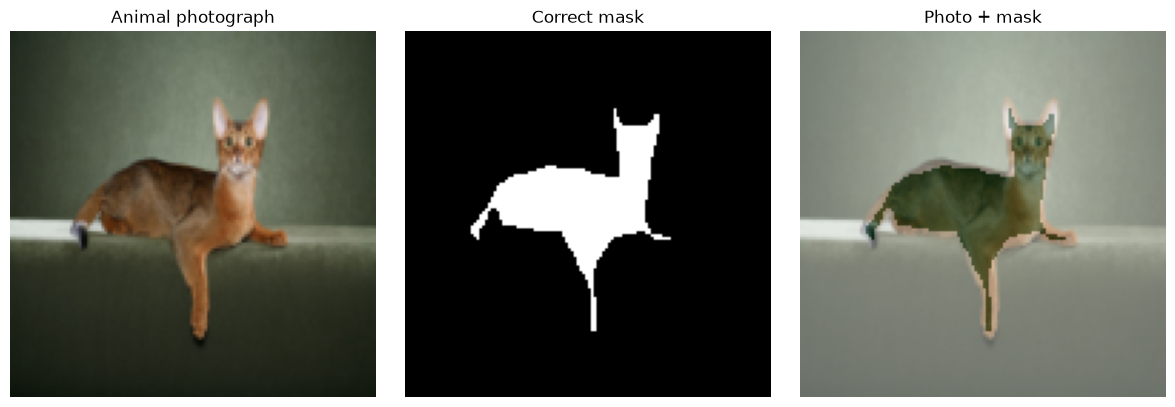

In [ ]:
i = 0  # Change this number to see another example.
row = df.iloc[i]
image, mask = row["image"], row["mask"]

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(image); axes[0].set_title("Animal photograph")
axes[1].imshow(mask, cmap="gray", vmin=0, vmax=1); axes[1].set_title("Correct mask")
axes[2].imshow(image)
axes[2].imshow(mask, cmap="Greens", alpha=0.4, vmin=0, vmax=1)
axes[2].set_title("Photo + mask")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.show()

## Step 8 — Split the photographs into training and validation sets

**Training** pictures teach the model. **Validation** pictures check its predictions on examples it did not train on.

In [ ]:
train_df, val_df = train_test_split(
    df, test_size=0.2, random_state=SEED, shuffle=True
)
print("Training photos:", len(train_df))
print("Validation photos:", len(val_df))

Training photos: 640
Validation photos: 160


## Step 9 — Turn our DataFrame into arrays for Keras

`X` contains photos, `y` contains the correct masks. Divide photo pixels by 255 so their values go from 0 to 1. Each mask has **one channel** because it is black and white.

In [ ]:
X_train = np.stack(train_df["image"].to_list()).astype("float32") / 255.0
X_val = np.stack(val_df["image"].to_list()).astype("float32") / 255.0

y_train = np.stack(train_df["mask"].to_list()).astype("float32")[..., None]
y_val = np.stack(val_df["mask"].to_list()).astype("float32")[..., None]

print("Training photos:", X_train.shape)  # (number, 128, 128, 3)
print("Training masks: ", y_train.shape)  # (number, 128, 128, 1)

Training photos: (640, 128, 128, 3)
Training masks:  (640, 128, 128, 1)


# Intermediary augmentation step
### Before Step 10 below, think perhaps of the different transformations that could be done to enhance the data set: rotation, zoom, translation, brightness, contrast adjustment, gaussian noise and horizontal flipping. Additional notebooks show these examples.

## Step 10 — Build a small CNN 🧠

A **convolution** helps the computer recognise visual patterns. **Pooling** makes the image smaller; **upsampling** brings it back to mask size. The final layer predicts a number between 0 and 1 for every pixel.

This is a deliberately small encoder–decoder model for classroom demonstrations, not a state-of-the-art segmentation system.

In [ ]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(128, 128, 3)),
    tf.keras.layers.Conv2D(16, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(),              # 128 → 64 pixels
    tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(),              # 64 → 32 pixels
    tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
    tf.keras.layers.UpSampling2D(),              # 32 → 64 pixels
    tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
    tf.keras.layers.UpSampling2D(),              # 64 → 128 pixels
    tf.keras.layers.Conv2D(16, 3, padding="same", activation="relu"),
    tf.keras.layers.Conv2D(1, 1, activation="sigmoid")  # 1 number per pixel
])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 128, 128, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 64, 64, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 64, 64, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_2 (UpSampling2D)  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_9 (Conv2D)               │ (None, 64, 64, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_3 (UpSampling2D)  │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 128, 128, 16)   │         4,624 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 128, 128, 1)    │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 46,689 (182.38 KB)

 Trainable params: 46,689 (182.38 KB)

 Non-trainable params: 0 (0.00 B)

## Step 11 — Compile the model

**Adam** adjusts the CNN. **Binary cross-entropy** measures mask prediction errors; **binary accuracy** is a quick indicator (but can be misleading if there is lots of background).

In [ ]:
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["binary_accuracy"]
)
print("Our model is ready to learn!")

Our model is ready to learn!


## Step 12 — Train with one line of Keras code

An **epoch** means going through the training set once. Try five epochs at first. Training may take a while on a CPU.

In [ ]:
EPOCHS = 5
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=16
)

Epoch 1/5
40/40 ━━━━━━━━━━━━━━━━━━━━ 7s 145ms/step - binary_accuracy: 0.6892 - loss: 0.6075 - val_binary_accuracy: 0.6908 - val_loss: 0.5632
Epoch 2/5
40/40 ━━━━━━━━━━━━━━━━━━━━ 6s 144ms/step - binary_accuracy: 0.6892 - loss: 0.5572 - val_binary_accuracy: 0.6908 - val_loss: 0.5393
Epoch 3/5
40/40 ━━━━━━━━━━━━━━━━━━━━ 6s 150ms/step - binary_accuracy: 0.6892 - loss: 0.5360 - val_binary_accuracy: 0.6908 - val_loss: 0.5150
Epoch 4/5
40/40 ━━━━━━━━━━━━━━━━━━━━ 6s 158ms/step - binary_accuracy: 0.7106 - loss: 0.5190 - val_binary_accuracy: 0.7271 - val_loss: 0.5051
Epoch 5/5
40/40 ━━━━━━━━━━━━━━━━━━━━ 6s 156ms/step - binary_accuracy: 0.7399 - loss: 0.5037 - val_binary_accuracy: 0.7425 - val_loss: 0.4947


## Step 13 — Plot how training went

Smaller loss is usually better. Compare training and validation curves to see whether the model is improving on unseen images.

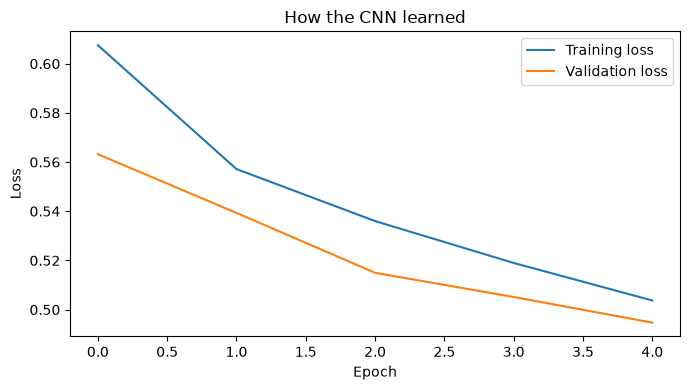

In [ ]:
plt.figure(figsize=(7, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("How the CNN learned")
plt.legend()
plt.tight_layout()
plt.show()

## Step 14 — Predict a mask from **one** new photo ✨

Select one image from the validation set. `predict()` returns one probability per pixel. Values greater than `0.5` become white (animal); the rest become black (background).

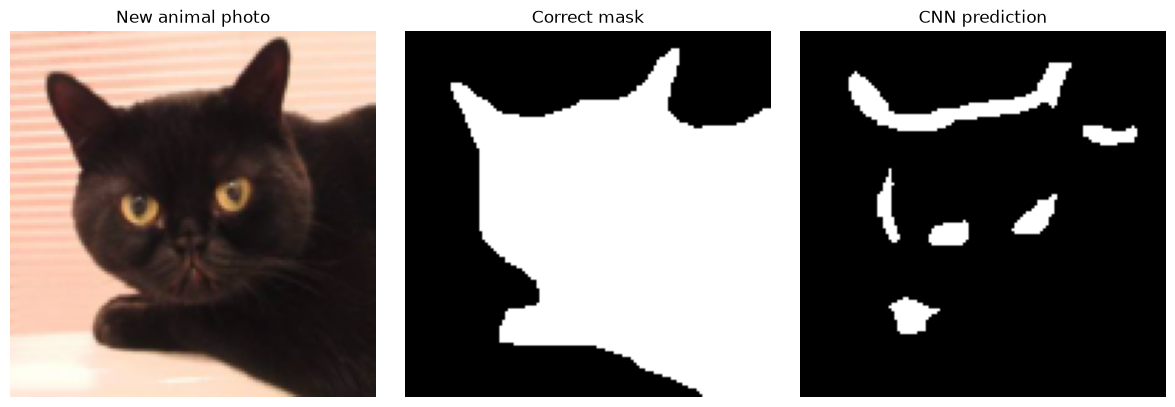

In [ ]:
i = 0  # Try another number to test a different validation photo.
row = val_df.iloc[i]

# Give Keras one photo, with an extra dimension for batch size 1.
one_image = row["image"].astype("float32") / 255.0
probabilities = model.predict(one_image[None, ...], verbose=0)[0, :, :, 0]
predicted_mask = (probabilities > 0.5).astype("uint8")

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(row["image"]); axes[0].set_title("New animal photo")
axes[1].imshow(row["mask"], cmap="gray", vmin=0, vmax=1); axes[1].set_title("Correct mask")
axes[2].imshow(predicted_mask, cmap="gray", vmin=0, vmax=1); axes[2].set_title("CNN prediction")
for ax in axes: ax.axis("off")
plt.tight_layout()
plt.show()

## Step 15 — Measure overlap (IoU)

**Intersection over Union (IoU)** compares predicted and correct animal pixels. A score of 1 is perfect; 0 means no overlap.

In [ ]:
true_mask = row["mask"].astype(bool)
pred_mask = predicted_mask.astype(bool)
intersection = np.logical_and(true_mask, pred_mask).sum()
union = np.logical_or(true_mask, pred_mask).sum()
iou = intersection / union if union else 1.0
print(f"IoU for this photograph: {iou:.3f}")

IoU for this photograph: 0.001


## Step 16 — Compare predictions for several photographs

This repeats the **single-picture prediction** on four validation photos. It is not a new training step.

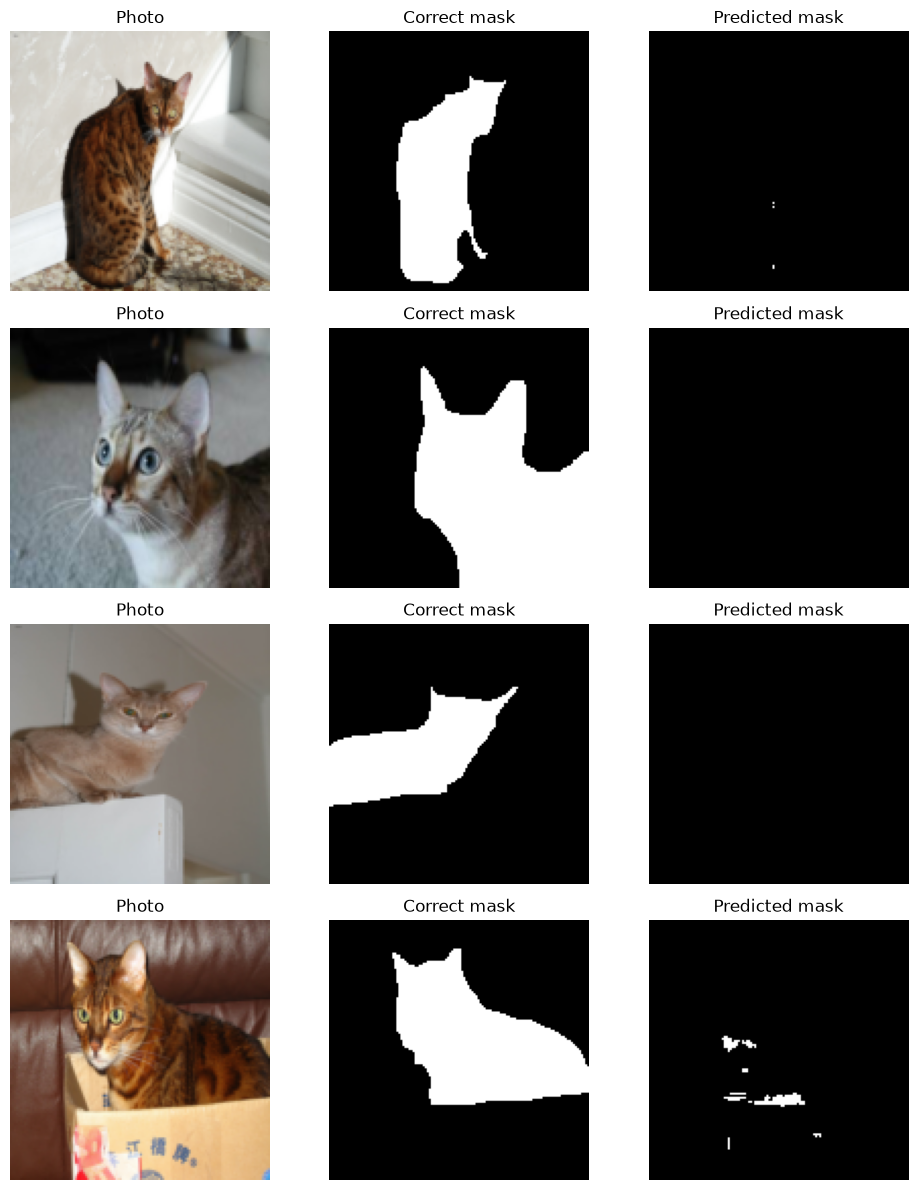

In [ ]:
number_to_show = min(4, len(val_df))
fig, axes = plt.subplots(number_to_show, 3,
                         figsize=(10, 3 * number_to_show), squeeze=False)

for i in range(number_to_show):
    row = val_df.iloc[i]
    one_image = row["image"].astype("float32") / 255.0
    probability = model.predict(one_image[None, ...], verbose=0)[0, :, :, 0]
    predicted = probability > 0.5

    for ax, picture, title in zip(axes[i],
                                  [row["image"], row["mask"], predicted],
                                  ["Photo", "Correct mask", "Predicted mask"]):
        ax.imshow(picture, cmap=None if title == "Photo" else "gray")
        ax.set_title(title)
        ax.axis("off")
plt.tight_layout()
plt.show()

## Step 17 — Save the model and one predicted mask

You can load the saved `.keras` model later, without retraining it. We also save the prediction from Step 14 as a PNG.

In [ ]:
model.save("animal_segmentation.keras")
Image.fromarray(predicted_mask * 255).save("predicted_animal_mask.png")
print("Saved animal_segmentation.keras and predicted_animal_mask.png")

Saved animal_segmentation.keras and predicted_animal_mask.png


## Step 18 — Student exercises 🎯

1. **Explore:** Change `i` in Step 7 to look at another animal and its mask.
2. **Predict:** Change `i` in Step 14. Is the result better for some animals?
3. **Train longer:** Change `EPOCHS` from 5 to 10 and compare the losses.
4. **Try more data:** Change `MAX_IMAGES` to `None` if you have many image-mask pairs.
5. **Think:** Why does every photo need its own *correct* mask?
6. **Experiment:** Change the decision threshold `0.5` to `0.7`. What changes?

**Troubleshooting:**
- `Folder not found` → check that `animal_dataset/animals` and `animal_dataset/masks` are beside this notebook, or edit `DATA_FOLDER`.
- `Need at least two matching ...` → check matching names (e.g. `dog_1.jpg` and `dog_1.png`).
- Empty or strange masks → check `MASK_FORMAT`; Oxford trimaps use 1/2/3 and binary masks use 0/255.
- Out of memory → reduce `MAX_IMAGES` or lower `IMAGE_SIZE` (and update model input and the two resize comments accordingly).

